# Hallucination probing in Colab

Select **Runtime → Change runtime type → T4 GPU** and run the cells in order. Authorize the Google Drive mount when prompted. If you choose a gated Hugging Face model, accept its access terms and add a Colab secret named `HF_TOKEN` with notebook access.

The default is a smoke run on 64 questions per dataset and layers 4 and 14 (zero-indexed). For the full experiment, set `SMOKE_RUN = False` in the settings cell. Your smoke and full runs use different Drive folders.

In [1]:
import subprocess
import sys
from pathlib import Path

REPO = Path("/content/llm_truth_probe_colab")
BRANCH = "codex/colab-pipeline"
if not REPO.exists():
    subprocess.run(
        ["git", "clone", "--branch", BRANCH, "--single-branch",
         "https://github.com/mananparmar05/llm_truth_probe.git", str(REPO)],
        check=True,
    )
subprocess.run(["git", "log", "-1", "--oneline"], cwd=REPO, check=True)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "transformers~=4.57.0", "accelerate>=1.1,<2", "bitsandbytes>=0.46,<1",
     "h5py", "joblib", "matplotlib", "pandas", "scikit-learn", "tqdm"],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers~=4.57.0', 'accelerate>=1.1,<2', 'bitsandbytes>=0.46,<1', 'h5py', 'joblib', 'matplotlib', 'pandas', 'scikit-learn', 'tqdm'], returncode=0)

In [2]:
import os
from google.colab import drive, userdata

drive.mount("/content/drive")
try:
    hf_token = userdata.get("HF_TOKEN")
except userdata.SecretNotFoundError:
    hf_token = None
if hf_token:
    os.environ["HF_TOKEN"] = hf_token
del hf_token

SMOKE_RUN = True
MODEL = "Qwen/Qwen2.5-7B"
REVISION = "main"
BATCH_SIZE = 4
PROBES = ["logistic_regression", "svm"]  # Add "mlp" for a longer run.
RESULT_NAME = "results"  # Change for a different probe list on the same activations.
RUN_NAME = "qwen-smoke" if SMOKE_RUN else "qwen-full"
OUTPUT = Path("/content/drive/MyDrive/llm_truth_probe") / RUN_NAME

def pipeline(command, *options):
    subprocess.run(
        [sys.executable, "-u", "-m", "probing.colab_pipeline", command,
         "--output", str(OUTPUT), *options],
        cwd=REPO, check=True,
    )

Mounted at /content/drive


## Extract activations

The full run uses both benchmarks and all layers. The 4-bit model runs on the GPU. Float16 activation shards go to Drive and take up to about 4.1 GiB before compression with the default full model. Rerun with the same settings and folder after a disconnect to skip completed shards. If you change extraction settings, choose a new `RUN_NAME`.

In [3]:
smoke_options = ["--limit", "64", "--layers", "4", "14"] if SMOKE_RUN else []
pipeline("extract", "--model", MODEL, "--revision", REVISION,
         "--batch-size", str(BATCH_SIZE), *smoke_options)

## Train and evaluate

The CPU fits probes from one transformer layer at a time. Each dataset gets one final test score for the probe selected by validation AUROC. Cross-dataset curves use logistic probes fitted on source train rows and scored on target test rows. If extraction is complete, you can resume this step on a CPU runtime by running setup, settings, and this cell.

In [4]:
pipeline("train", "--result-name", RESULT_NAME, "--probes", *PROBES)

## View results

The Drive run contains the model revision, row split assignments, activation shards, fitted probes, evaluation CSVs, and plots. Use the full-run test metrics for reporting. The smoke run checks the workflow.

,dataset,layer,probe,checkpoint,validation_auroc,auroc,f1,accuracy
0,truthfulqa,14,logistic_regression,truthfulqa_layer14_logistic_regression.pkl,0.666667,0.734694,0.615385,0.642857
1,halueval,4,logistic_regression,halueval_layer04_logistic_regression.pkl,1.000000,1.000000,0.923077,0.928571


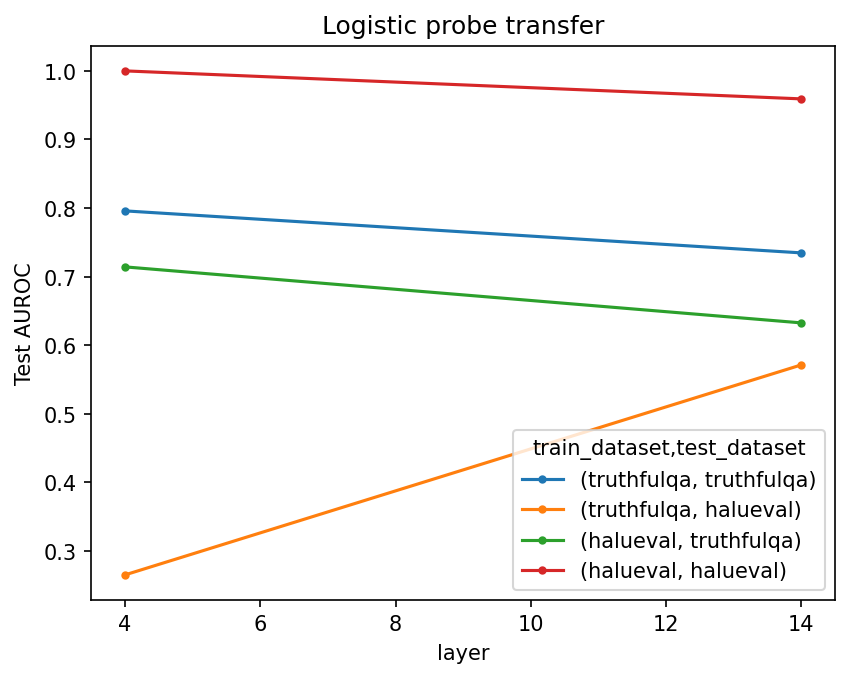

Results folder: /content/drive/MyDrive/llm_truth_probe/qwen-smoke/results


In [5]:
import pandas as pd
from IPython.display import Image, display

results = OUTPUT / RESULT_NAME
display(pd.read_csv(results / "test_metrics.csv"))
display(Image(filename=str(results / "cross_dataset.png")))
print(f"Results folder: {results}")

## Run controls

Run after training completes. This cell uses the current Drive output folder and runs on CPU. It uses a separate checkout so that resuming extraction keeps the same code revision. A saved smoke-run output uses `qwen-smoke`; a completed full run uses `qwen-full`.

In [ ]:
controls_repo = Path("/content/llm_truth_probe_controls")
if not controls_repo.exists():
    subprocess.run(
        ["git", "clone", "--single-branch", "--branch", "codex/colab-controls",
         "https://github.com/mananparmar05/llm_truth_probe.git", str(controls_repo)],
        check=True,
    )

subprocess.run(
    [sys.executable, "-u", "-m", "probing.colab_pipeline", "controls",
     "--output", str(OUTPUT), "--result-name", RESULT_NAME],
    cwd=controls_repo, check=True,
)
display(Image(filename=str(results / "control_comparison.png")))
print(f"Control metrics: {results / 'control_metrics.csv'}")